# Лабораторная работа №1–2
## Экономика информатизации
### Оценка экономической эффективности внедрения облачной CRM

**Задача.** Компания «ТехноПром» рассматривает вопрос о внедрении облачной CRM-системы для отдела продаж.
Нужно оценить прямой эффект, затраты на внедрение, финансовые показатели эффективности (NPV, срок
окупаемости, ROI) и проанализировать нематериальные эффекты.

## 1. Исходные данные

| Параметр | Значение |
|---|---|
| Количество менеджеров в отделе продаж | 15 чел. |
| Средняя зарплата менеджера | 120 000 руб./мес. |
| Экономия времени на рутинных операциях после внедрения CRM | 20% |
| Процент рабочего времени, тратимый на рутинные операции (без CRM) | 30% |
| Рост продаж после внедрения CRM (умеренный прогноз) | 8% в год |
| Текущий годовой оборот отдела продаж | 72 млн руб. |
| Стоимость облачной CRM на год (на пользователя) | 24 000 руб./чел. |
| Время на обучение внедрению CRM (потеря времени на адаптацию) | 1 месяц |
| Горизонт оценки | 3 года |
| Ставка дисконтирования | 12% |
| Налог на прибыль | 20% |

### 1.1. Допущения для недостающих данных

Условие не даёт три важные вещи, без которых модель посчитать нельзя. Фиксируем их явно, чтобы результат
был проверяемым и воспроизводимым:

1. **Чистая рентабельность продаж — 20% после налога.** В условии не указана себестоимость/маржа компании,
   поэтому прирост выручки от роста продаж нельзя считать «чистой прибылью напрямую» — такая выручка всё ещё
   несёт свою долю затрат (закупка, обслуживание сделки и т.д.). 20% — разумная оценка для B2B-услуг/продаж
   с не самой низкой маржой (при другой реальной марже компании цифры ниже линейно пересчитываются).
2. **Сокращения штата нет.** Освобождённое рутинной автоматизацией время (6% рабочего времени менеджеров)
   не конвертируется в прямую экономию фонда оплаты труда — зарплаты не снижаются. Это время — ресурс,
   который и позволяет менеджерам продавать больше; его эффект уже заложен в прогнозе роста продаж (8%).
   Если бы мы одновременно считали и экономию ФОТ, и рост продаж как независимые источники выгоды — это было
   бы задвоением одного и того же эффекта.
3. **Потери на обучении считаем через упущенную прибыль**, а не через стоимость рабочего времени: за месяц
   адаптации компания недополучает часть обычной прибыли с оборота — она оценивается через ту же маржу 20%,
   что и остальная модель (это методологически единообразнее, чем привязывать потери к доле ФОТ).

In [1]:
# Исходные данные и допущения — в одном месте
params = {
    "managers": 15,                  # количество менеджеров, чел.
    "salary_month": 120_000,         # средняя зарплата менеджера, руб./мес.
    "routine_share": 0.30,           # доля времени на рутинные операции без CRM
    "routine_reduction": 0.20,       # сокращение времени на рутину после CRM
    "sales_growth": 0.08,            # рост продаж после внедрения CRM, в год
    "annual_turnover": 72_000_000,   # текущий годовой оборот отдела продаж, руб.
    "crm_per_user_year": 24_000,     # стоимость CRM на пользователя, руб./год
    "training_months": 1,            # время на обучение (адаптацию), мес.
    "horizon_years": 3,              # горизонт оценки, лет
    "discount_rate": 0.12,           # ставка дисконтирования, годовых
    "tax_rate": 0.20,                # налог на прибыль
    "net_profit_margin": 0.20,       # ДОПУЩЕНИЕ: чистая рентабельность продаж после налога
}

for key, val in params.items():
    print(f"{key:<20} {val}")

managers             15
salary_month         120000
routine_share        0.3
routine_reduction    0.2
sales_growth         0.08
annual_turnover      72000000
crm_per_user_year    24000
training_months      1
horizon_years        3
discount_rate        0.12
tax_rate             0.2
net_profit_margin    0.2


## 2. Прямой эффект от внедрения CRM

### 2.1. Высвобождение рабочего времени (справочно, не входит в денежный поток)

Доля высвобождаемого времени = доля времени на рутинные операции × экономия этого времени после CRM.
Как объяснено в допущении 2 — это НЕ отдельная денежная экономия, а ресурс, который уже отражён в росте
продаж. Переводим его в рубли только для справки, чтобы показать масштаб эффекта.

In [2]:
annual_salary_fund = params["managers"] * params["salary_month"] * 12
released_time_share = params["routine_share"] * params["routine_reduction"]
potential_capacity_value = annual_salary_fund * released_time_share

# Прямой денежной экономии ФОТ в модели нет (см. допущение 2) — сокращения штата не предполагается.
salary_cash_saving = 0

print(f"Годовой ФОТ отдела продаж: {annual_salary_fund:,.0f} руб.".replace(",", " "))
print(f"Высвобождается рабочего времени: {released_time_share:.0%}")
print(f"Зарплатный эквивалент этого времени (справочно): {potential_capacity_value:,.0f} руб./год".replace(",", " "))
print(f"Фактическая денежная экономия ФОТ в модели: {salary_cash_saving:,.0f} руб./год")

Годовой ФОТ отдела продаж: 21 600 000 руб.
Высвобождается рабочего времени: 6%
Зарплатный эквивалент этого времени (справочно): 1 296 000 руб./год
Фактическая денежная экономия ФОТ в модели: 0 руб./год


### 2.2. Дополнительная чистая прибыль от роста продаж

$$\text{Доп. выручка} = \text{Оборот} \times \text{Рост продаж}$$
$$\text{Доп. чистая прибыль} = \text{Доп. выручка} \times \text{Рентабельность (20\%)}$$

In [3]:
additional_revenue = params["annual_turnover"] * params["sales_growth"]
additional_net_profit = additional_revenue * params["net_profit_margin"]

print(f"Дополнительная выручка при росте {params['sales_growth']:.0%}: {additional_revenue:,.0f} руб./год".replace(",", " "))
print(f"Дополнительная чистая прибыль (при марже {params['net_profit_margin']:.0%}): {additional_net_profit:,.0f} руб./год".replace(",", " "))

Дополнительная выручка при росте 8%: 5 760 000 руб./год
Дополнительная чистая прибыль (при марже 20%): 1 152 000 руб./год


## 3. Затраты на внедрение

### 3.1. Стоимость лицензий за 3 года

Лицензия — операционный расход, уменьшающий налогооблагаемую прибыль, поэтому даём и валовую, и
посленалоговую (реальную денежную) стоимость — её мы и будем использовать в денежном потоке.

In [4]:
annual_license_cost = params["managers"] * params["crm_per_user_year"]
total_license_cost = annual_license_cost * params["horizon_years"]
annual_license_cost_after_tax = annual_license_cost * (1 - params["tax_rate"])

print(f"Лицензии за год (валовая стоимость): {annual_license_cost:,.0f} руб.".replace(",", " "))
print(f"Лицензии за {params['horizon_years']} года: {total_license_cost:,.0f} руб.".replace(",", " "))
print(f"Лицензии за год после налогового эффекта: {annual_license_cost_after_tax:,.0f} руб.".replace(",", " "))

Лицензии за год (валовая стоимость): 360 000 руб.
Лицензии за 3 года: 1 080 000 руб.
Лицензии за год после налогового эффекта: 288 000 руб.


### 3.2. Потери от снижения производительности в первый месяц обучения

Один месяц сотрудники тратят на адаптацию к системе — компания в этот период недополучает часть обычной
прибыли с оборота (упущенная выгода), оценённую через ту же маржу 20%:

$$\text{Потери на обучении} = \frac{\text{Оборот}}{12} \times \text{Маржа} \times \text{Месяцы обучения}$$

In [5]:
monthly_turnover = params["annual_turnover"] / 12
training_profit_loss = monthly_turnover * params["net_profit_margin"] * params["training_months"]

print(f"Месячный оборот: {monthly_turnover:,.0f} руб.".replace(",", " "))
print(f"Потери на обучении (единовременно, момент t=0): {training_profit_loss:,.0f} руб.".replace(",", " "))

Месячный оборот: 6 000 000 руб.
Потери на обучении (единовременно  момент t=0): 1 200 000 руб.


## 4. Финансовые показатели эффективности

### 4.1. Денежные потоки по годам

- t = 0: только потери на обучении (единовременная инвестиция).
- t = 1..3: ежегодный чистый эффект = доп. чистая прибыль от роста продаж − лицензии после налога
  (одинаковый каждый год, т.к. рост продаж 8% берётся как фиксированный годовой эффект, а не
  накопительным итогом — используем ту же трактовку, что и в сценарном анализе ниже).

In [6]:
import numpy as np

years = np.arange(params["horizon_years"] + 1)   # 0,1,2,3
cash_flows = np.zeros(len(years))

cash_flows[0] = -training_profit_loss
annual_net_cash_flow = additional_net_profit - annual_license_cost_after_tax
cash_flows[1:] = annual_net_cash_flow

cumulative_cash_flows = np.cumsum(cash_flows)

print(f"Ежегодный чистый эффект (Год 1–3): {annual_net_cash_flow:,.0f} руб./год".replace(",", " "))
print()
print(f"{'Год':>4} | {'Поток, руб.':>14} | {'Накопленный поток, руб.':>24}")
for y, cf, cum in zip(years, cash_flows, cumulative_cash_flows):
    print(f"{y:>4} | {cf:>14,.0f} | {cum:>24,.0f}".replace(",", " "))

Ежегодный чистый эффект (Год 1–3): 864 000 руб./год

 Год |    Поток, руб. |  Накопленный поток, руб.
   0 |     -1 200 000 |               -1 200 000
   1 |        864 000 |                 -336 000
   2 |        864 000 |                  528 000
   3 |        864 000 |                1 392 000


### 4.2. NPV проекта (ставка дисконтирования r = 12%)

$$NPV = \sum_{t=0}^{3} \frac{CF_t}{(1+r)^t}$$

In [7]:
discount_factors = 1 / (1 + params["discount_rate"]) ** years
discounted_cash_flows = cash_flows * discount_factors
npv = discounted_cash_flows.sum()

print(f"{'Год':>4} | {'CF, руб.':>14} | {'Коэфф. дисконт.':>16} | {'Дисконт. поток, руб.':>20}")
for y, cf, df, dcf in zip(years, cash_flows, discount_factors, discounted_cash_flows):
    print(f"{y:>4} | {cf:>14,.0f} | {df:>16.4f} | {dcf:>20,.0f}".replace(",", " "))

print(f"\nNPV = {npv:,.0f} руб.".replace(",", " "))
print("Проект экономически выгоден" if npv > 0 else "Проект экономически невыгоден")

 Год |       CF, руб. |  Коэфф. дисконт. | Дисконт. поток, руб.
   0 |     -1 200 000 |           1.0000 |           -1 200 000
   1 |        864 000 |           0.8929 |              771 429
   2 |        864 000 |           0.7972 |              688 776
   3 |        864 000 |           0.7118 |              614 978

NPV = 875 182 руб.
Проект экономически выгоден


### 4.3. Простой срок окупаемости

Год, когда накопленный (недисконтированный) денежный поток впервые становится неотрицательным, плюс
уточнение внутри года (считаем поступление равномерным в течение года).

In [8]:
payback_year = None
for y, cum in zip(years, cumulative_cash_flows):
    if cum >= 0:
        payback_year = int(y)
        break

prev_cum = cumulative_cash_flows[payback_year - 1]
this_flow = cash_flows[payback_year]
payback_precise = (payback_year - 1) + (-prev_cum / this_flow)

print(f"Накопленный поток впервые неотрицателен в {payback_year}-м году")
print(f"Точный срок окупаемости: {payback_precise:.2f} года (≈ {payback_precise*12:.1f} мес.)")

Накопленный поток впервые неотрицателен в 2-м году
Точный срок окупаемости: 1.39 года (≈ 16.7 мес.)


### 4.4. ROI проекта

In [9]:
total_project_cost = training_profit_loss + annual_license_cost_after_tax * params["horizon_years"]
net_result = cash_flows.sum()
roi = net_result / total_project_cost * 100

print(f"Суммарные затраты за {params['horizon_years']} года: {total_project_cost:,.0f} руб.".replace(",", " "))
print(f"Суммарный чистый результат (недисконтированный): {net_result:,.0f} руб.".replace(",", " "))
print(f"ROI проекта: {roi:.1f}%")

Суммарные затраты за 3 года: 2 064 000 руб.
Суммарный чистый результат (недисконтированный): 1 392 000 руб.
ROI проекта: 67.4%


### Визуализация: денежные потоки по годам

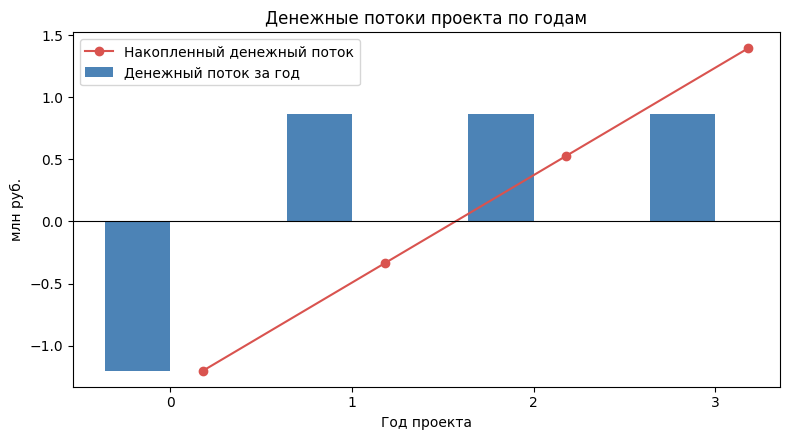

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(years - 0.18, cash_flows / 1_000_000, width=0.36, label="Денежный поток за год", color="#4c83b6")
ax.plot(years + 0.18, cumulative_cash_flows / 1_000_000, marker="o",
        label="Накопленный денежный поток", color="#d9534f")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(years)
ax.set_xlabel("Год проекта")
ax.set_ylabel("млн руб.")
ax.set_title("Денежные потоки проекта по годам")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Анализ чувствительности к темпу роста продаж

Главный рычаг модели — предположение о росте продаж (8% в год). Проверим, как меняется NPV в
пессимистичном (5%) и оптимистичном (12%) сценариях при тех же марже, стоимости CRM, обучении и горизонте.

In [11]:
growth_scenarios = {
    "Пессимистичный": 0.05,
    "Базовый": params["sales_growth"],
    "Оптимистичный": 0.12,
}

print(f"{'Сценарий':<16}{'Рост продаж':>14}{'Чистый эффект/год':>20}{'NPV, руб.':>16}")
scenario_npvs = {}
for name, growth in growth_scenarios.items():
    scenario_profit = params["annual_turnover"] * growth * params["net_profit_margin"]
    scenario_flows = np.zeros(len(years))
    scenario_flows[0] = -training_profit_loss
    scenario_flows[1:] = scenario_profit - annual_license_cost_after_tax
    scenario_npv = (scenario_flows / (1 + params["discount_rate"]) ** years).sum()
    scenario_npvs[name] = scenario_npv
    print(f"{name:<16}{growth:>14.0%}{scenario_profit - annual_license_cost_after_tax:>20,.0f}{scenario_npv:>16,.0f}".replace(",", " "))

Сценарий           Рост продаж   Чистый эффект/год       NPV, руб.
Пессимистичный              5%             432 000        -162 409
Базовый                     8%             864 000         875 182
Оптимистичный              12%           1 440 000       2 258 637


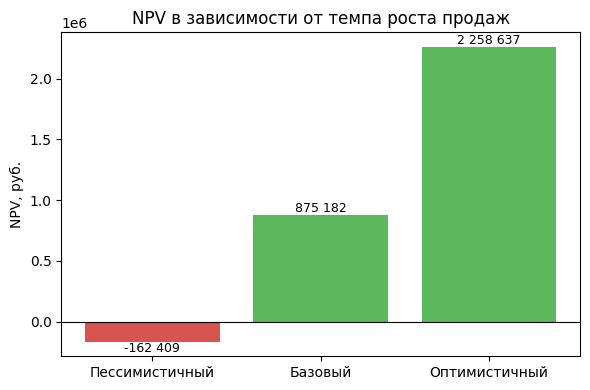

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
names = list(scenario_npvs.keys())
values = list(scenario_npvs.values())
colors = ["#d9534f" if v < 0 else "#5cb85c" for v in values]
ax.bar(names, values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("NPV, руб.")
ax.set_title("NPV в зависимости от темпа роста продаж")
for i, v in enumerate(values):
    ax.text(i, v, f"{v:,.0f}".replace(",", " "), ha="center",
            va="bottom" if v >= 0 else "top", fontsize=9)
plt.tight_layout()
plt.show()

**Вывод.** При пессимистичном сценарии (рост продаж всего 5% вместо 8%) NPV уходит в минус — проект
становится невыгодным. Это значит, что результат (в отличие от, например, стоимости лицензий) очень
чувствителен именно к точности прогноза роста продаж, а не к самой CRM-системе как таковой.

## 6. Нематериальные эффекты

### 6.1. Нематериальные выгоды от внедрения CRM

- Повышение качества обслуживания клиентов и рост удовлетворённости за счёт единой истории взаимодействий.
- Снижение риска потери клиентов и сделок при увольнении или замене менеджера (данные остаются в системе, а не в личных записях сотрудника).
- Более точная и прозрачная аналитика и отчётность по воронке продаж для руководства.
- Стандартизация и формализация бизнес-процессов отдела продаж.
- Повышение управляемости и прогнозируемости продаж, более обоснованное планирование.
- Рост удовлетворённости самих сотрудников за счёт снижения рутинной нагрузки.
- Создание основы (данных) для дальнейшей автоматизации — e-mail-рассылок, скоринга лидов, интеграции с другими системами.

### 6.2. Парадокс производительности Солоу

Парадокс производительности Солоу («компьютеры видны повсюду, кроме статистики производительности»)
указывает на то, что инвестиции в ИТ не всегда напрямую и быстро отражаются в измеримых финансовых
показателях. Применительно к данному проекту это означает следующее:

- Весь расчётный эффект (NPV, ROI) держится на одном прогнозном числе — 8% роста продаж, которое само
  предполагается как следствие внедрения CRM. Если менеджеры не станут активно пользоваться системой или
  процессы вокруг неё не перестроятся, прогноз не реализуется, а проект (см. раздел 5) может стать
  убыточным уже при 5% роста.
- Эффект от внедрения ИТ-системы часто проявляется с задержкой: период адаптации (в задаче — 1 месяц) на
  практике может затянуться, из-за чего реальные потери первого периода окажутся выше модельных.
- Высвобожденное рабочее время (раздел 2.1) не гарантированно конвертируется в рост продаж — менеджеры
  могут потратить его на другие задачи, и тогда даже базовый прогноз 8% не реализуется.
- Часть выгод (качество данных, управляемость, снижение рисков — раздел 6.1) носит качественный характер
  и не отражается в NPV и ROI напрямую, из-за чего формальная оценка эффективности может быть неполной
  в обе стороны: как недооценивать реальную пользу, так и переоценивать её, если прогноз роста продаж
  окажется слишком оптимистичным.

**Вывод.** При принятых допущениях (маржа 20%, без сокращения штата) проект показывает положительный, но
гораздо более скромный NPV (≈ 875 тыс. руб.), чем при наивном предположении «вся дополнительная выручка —
это прибыль». Результат сильно зависит от того, насколько точно оправдается прогноз роста продаж — при
нём ниже 5–6% в год проект перестаёт окупаться за 3 года.